Decision tree in regression - exercise 2

1. Import all necessary methods from libraries (or modules from these libraries).
2. Load a dataset from the diamonds.csv file, using the appropriate method from the Pandas library.
3. Divide the dataset into training and test datasets.
4. Initialize the decision tree model. Select a starting set of hyperparameters.
5. Train the decision tree model.
6. Generate a graph that visualizes how the trained model calculates predictions.
7. Calculate the metrics R2, MAE, MSE and RMSE.
8. Repeat steps 2, 3, 4 and 5 until you have an optimal model.

    To speed up the model building process:

    1. call the method that fits the data to the model,
    2. generate a graph that shows how the trained tree works,
    3. calculate the metrics of the model,
    4. Wrap it in a function that takes as arguments the values of the hyperparameters you want to set.

In [10]:
import pandas as pd

diamonds_df = pd.read_csv("data/diamonds.csv")
diamonds_df.head(15)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,7,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,8,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,9,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,10,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [11]:
diamonds_df = diamonds_df.drop("Unnamed: 0", axis=1)
diamonds_df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt 
from sklearn.tree import DecisionTreeRegressor

In [13]:
X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


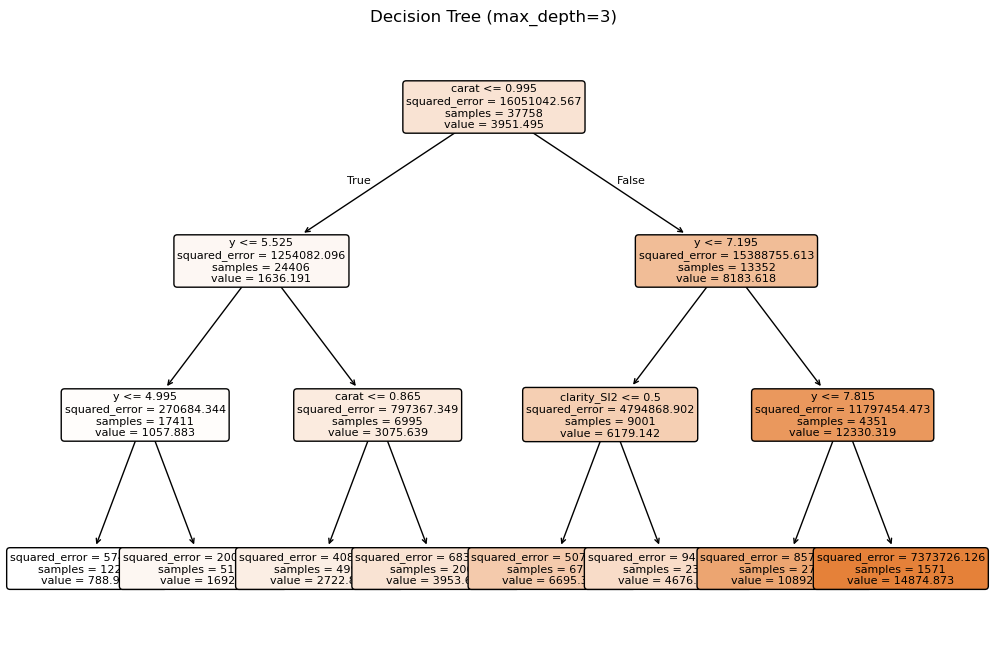

R2_score: 0.8748239431145767
MAE: 803.7925862453417
MSE: 1952241.1963503333
RMSE: 1397.2262509523407
R2_score: 0.8302082754717783
MAE: 1030.8976303099785
MSE: 2648065.514052485
RMSE: 1627.2877784990844
R2_score: 0.8748239431145767
MAE: 803.7925862453417
MSE: 1952241.1963503333
RMSE: 1397.2262509523407
R2_score: 0.914037184880916
MAE: 643.3075285309357
MSE: 1340672.914655979
RMSE: 1157.8743086604777
R2_score: 0.9422001625748033
MAE: 523.9702528161652
MSE: 901444.1465200109
RMSE: 949.4441250121099
R2_score: 0.9658939807928982
MAE: 395.7608501705988
MSE: 531916.2258047872
RMSE: 729.3258707908195


,max_depth,R2_score,MAE,MSE,RMSE
0,2,0.830208,1030.897630,2.648066e+06,1627.287778
1,3,0.874824,803.792586,1.952241e+06,1397.226251
2,5,0.914037,643.307529,1.340673e+06,1157.874309
3,7,0.942200,523.970253,9.014441e+05,949.444125
4,10,0.965894,395.760850,5.319162e+05,729.325871


In [14]:
from sklearn.tree import plot_tree

# Define a reusable workflow for training and comparing decision tree settings.
def decision_tree_regression_model(max_depth=3, random_state=42, feature_names=None, plot=True):
    # Build a regressor with the requested depth and a reproducible random state.
    reg_tree = DecisionTreeRegressor(max_depth=max_depth, random_state=random_state)

    # Train the model on the training partition only.
    reg_tree.fit(X_train, y_train)

    # Predict prices for the held-out test partition.
    y_pred = reg_tree.predict(X_test)

    # Optionally visualize the learned splits, labeling them with feature names.
    if plot:
        plt.figure(figsize=(12, 8))
        plot_tree(
            reg_tree,
            feature_names=X.columns if feature_names is None else feature_names,
            filled=True,
            rounded=True,
            fontsize=8,
        )
        plt.title(f"Decision Tree (max_depth={max_depth})")
        plt.show()

    # Compute several complementary measures of prediction quality and error.
    metrics = {
        "R2_score": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    }

    # Print the scores so each call provides an immediate evaluation summary.
    print(f"R2_score: {metrics['R2_score']}")
    print(f"MAE: {metrics['MAE']}")
    print(f"MSE: {metrics['MSE']}")
    print(f"RMSE: {metrics['RMSE']}")

    # Return the fitted estimator and scores for reuse and comparison.
    return reg_tree, metrics


# Fit and visualize a baseline tree with maximum depth 3.
model, metrics = decision_tree_regression_model(
    max_depth=3,
    feature_names=X.columns,
    plot=True,
)

# Compare several candidate maximum depths using the same fixed data split.
depths = [2, 3, 5, 7, 10]
results = []

# Store each candidate's metrics; hide plots to keep the comparison concise.
for depth in depths:
    _, depth_metrics = decision_tree_regression_model(
        max_depth=depth,
        feature_names=X.columns,
        plot=False,
    )
    results.append({"max_depth": depth, **depth_metrics})

# Put the collected scores in a table for side-by-side comparison.
results_df = pd.DataFrame(results)
results_df

## Summary of the Decision Tree Regression

We used the diamonds dataset to predict `price`. The categorical predictors were one-hot encoded because scikit-learn's `DecisionTreeRegressor` requires numeric input; it does not accept raw text categories. We then used a fixed 70/30 train/test split (random state 42) so the tested tree depths can be compared on the same holdout data.

The `decision_tree_regression_model` function trains a tree for a chosen `max_depth`, optionally plots its splits, calculates R2, MAE, MSE, and RMSE on the test set, and returns both the fitted model and metrics. It is called once to display a depth-3 baseline and again for depths 2, 3, 5, 7, and 10; the `results_df` table compares those candidates.

For the depth-3 baseline, the observed scores were approximately **R2 = 0.8748**, **MAE = 803.79**, **MSE = 1,952,241.20**, and **RMSE = 1,397.23**. The comparison table should be used to select among the tested depths; these baseline results alone do not establish that depth 3 is optimal. Lower MAE, MSE, and RMSE indicate smaller prediction errors, while a higher R2 indicates more variance explained.

The displayed tree is deliberately limited to depth 3 so its decision rules remain readable. The deeper candidate trees are evaluated without plotting each one.